In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter
from multifractal_networks.utils.motifs import MotifGenerator

# Load Network

In [4]:
filename = './test_networks/celegans_neural_undirected.csv'
G = nx.read_edgelist(filename, delimiter = ',')

In [5]:
len(G)

543

In [6]:
2 * G.number_of_edges() / G.number_of_nodes()

7.911602209944752

In [11]:
for m_size in [2,3,5,6,7,10,11]:
    print(m_size,' k_max: ',int(np.log(len(G))/np.log(m_size))+1)

2  k_max:  10
3  k_max:  6
5  k_max:  4
6  k_max:  4
7  k_max:  4
10  k_max:  3
11  k_max:  3


# Init Fitter

In [9]:
mfnf = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 200,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.073294
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:01.767063


In [10]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 2148},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 34419},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 0},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 400490},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 0},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'count': 325683},
 {'name': 'three_loop_out',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 0],
         [1, 1, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 0},
 {'name': 'four_loop'

# Grid Search

In [12]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,  'k': [1,10]},
                {'m': 3,  'k': [1,6]},
                {'m': 5,  'k': [1,4]},
                {'m': 6,  'k': [1,4]},
                {'m': 7,  'k': [1,4]},
                {'m': 10, 'k': [1,3]},
                {'m': 11, 'k': [1,3]},],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'kl_energy'
)

[I 2025-01-26 13:55:00,301] A new study created in memory with name: no-name-aef5a6f0-2cb5-44ea-bd75-ef8efa319e9b


Grid Search requires 9 trials...


[I 2025-01-26 13:55:46,523] Trial 0 finished with value: 6.2386871471035565 and parameters: {'m': 2, 'k': 8}. Best is trial 0 with value: 6.2386871471035565.
[I 2025-01-26 13:56:20,639] Trial 1 finished with value: 6.736854321901203 and parameters: {'m': 2, 'k': 3}. Best is trial 0 with value: 6.2386871471035565.
[I 2025-01-26 13:56:52,470] Trial 2 finished with value: 6.984405512700102 and parameters: {'m': 2, 'k': 2}. Best is trial 0 with value: 6.2386871471035565.
[I 2025-01-26 13:57:24,478] Trial 3 finished with value: 6.573191307318189 and parameters: {'m': 2, 'k': 5}. Best is trial 0 with value: 6.2386871471035565.
[I 2025-01-26 13:58:40,874] Trial 4 finished with value: 6.325092278454139 and parameters: {'m': 2, 'k': 9}. Best is trial 0 with value: 6.2386871471035565.
[I 2025-01-26 13:59:18,871] Trial 5 finished with value: 6.371602248529747 and parameters: {'m': 2, 'k': 7}. Best is trial 0 with value: 6.2386871471035565.
[I 2025-01-26 13:59:51,941] Trial 6 finished with value: 

Grid Search requires 5 trials...


[I 2025-01-26 14:02:06,282] Trial 0 finished with value: 5.345518335299192 and parameters: {'m': 3, 'k': 3}. Best is trial 0 with value: 5.345518335299192.
[I 2025-01-26 14:03:00,139] Trial 1 finished with value: 7.027336469926671 and parameters: {'m': 3, 'k': 1}. Best is trial 0 with value: 5.345518335299192.
[I 2025-01-26 14:04:04,981] Trial 2 finished with value: 5.714585565338475 and parameters: {'m': 3, 'k': 2}. Best is trial 0 with value: 5.345518335299192.
[I 2025-01-26 14:05:23,986] Trial 3 finished with value: 5.4303324313484165 and parameters: {'m': 3, 'k': 4}. Best is trial 0 with value: 5.345518335299192.
[I 2025-01-26 14:06:56,720] Trial 4 finished with value: 5.848780174869444 and parameters: {'m': 3, 'k': 5}. Best is trial 0 with value: 5.345518335299192.
[I 2025-01-26 14:06:56,722] A new study created in memory with name: no-name-0eafff6f-6ede-4f7c-8a09-fefd1bbd48a7


Grid Search requires 3 trials...


... (6 outputs left out)

[I 2025-01-26 14:54:33,757] Trial 0 finished with value: 5.364426947374199 and parameters: {'m': 10, 'k': 2}. Best is trial 0 with value: 5.364426947374199.
[I 2025-01-26 15:02:26,878] Trial 1 finished with value: 5.255061264331325 and parameters: {'m': 10, 'k': 1}. Best is trial 1 with value: 5.255061264331325.
[I 2025-01-26 15:02:26,879] A new study created in memory with name: no-name-15c5d948-50ee-4494-9be7-dbdd6da1a1ae


Grid Search requires 2 trials...


[I 2025-01-26 15:19:22,983] Trial 0 finished with value: 5.38160304465223 and parameters: {'m': 11, 'k': 2}. Best is trial 0 with value: 5.38160304465223.
[I 2025-01-26 15:29:43,443] Trial 1 finished with value: 5.195311025666223 and parameters: {'m': 11, 'k': 1}. Best is trial 1 with value: 5.195311025666223.


Best parameters:  {'m': 11, 'k': 1}
Best energy:  7.748470607019912
Best KL-divergence:  -0.005274533687845413
Best KLD augumented energy: 5.195311025666223
Best P matrix:
 [[9.41622365e-03 1.33194793e-03 1.94583778e-02 1.13573672e-12
  1.28212454e-01 6.76271210e-02 1.85360490e-01 0.00000000e+00
  1.67261505e-01 5.58745885e-10 6.13854391e-02]
 [1.33194793e-03 1.01166147e-02 0.00000000e+00 0.00000000e+00
  1.20675945e-02 4.84647791e-03 0.00000000e+00 6.14792477e-01
  1.13344293e-02 2.83950238e-02 3.65936227e-02]
 [1.94583778e-02 0.00000000e+00 8.14495583e-02 0.00000000e+00
  2.42314835e-02 1.09536389e-01 2.86375841e-10 0.00000000e+00
  0.00000000e+00 5.43374243e-02 2.06823891e-02]
 [1.13573672e-12 0.00000000e+00 0.00000000e+00 8.71189850e-01
  0.00000000e+00 2.16929708e-10 1.04944524e-11 2.90608375e-11
  3.02851747e-10 4.65371364e-11 1.84919310e-02]
 [1.28212454e-01 1.20675945e-02 2.42314835e-02 0.00000000e+00
  0.00000000e+00 4.71850866e-10 7.12483066e-01 0.00000000e+00
  3.94370496e-1

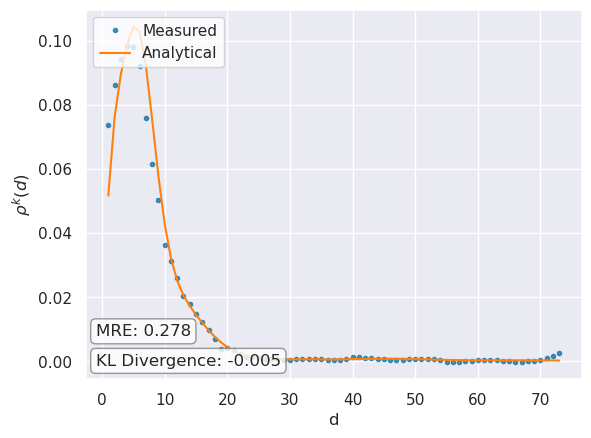

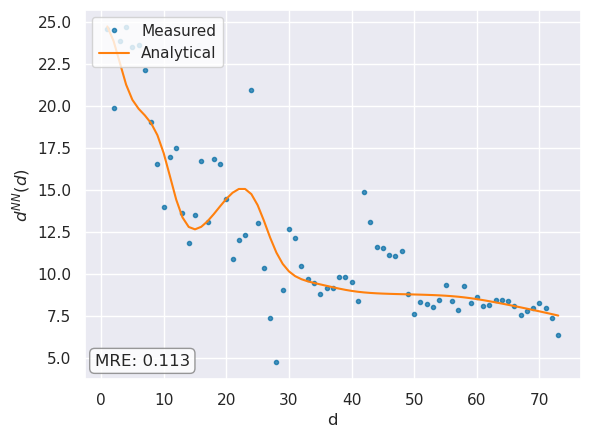

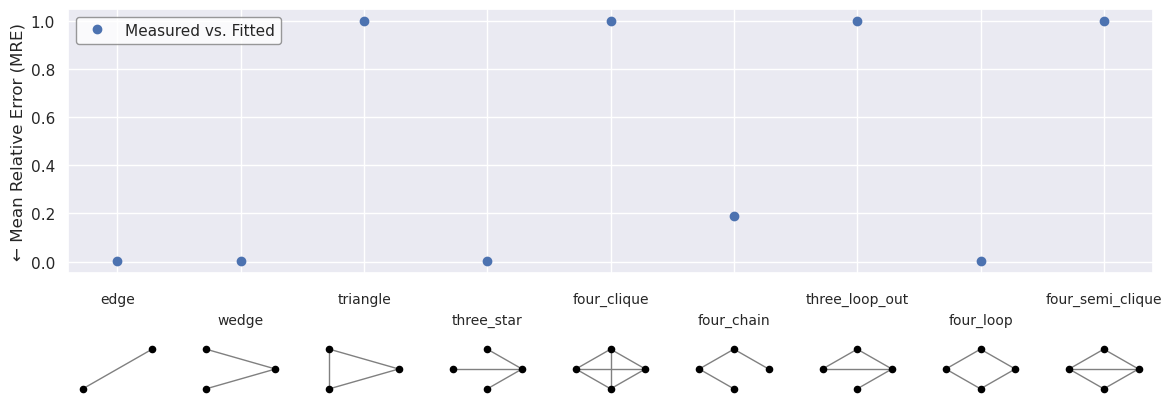

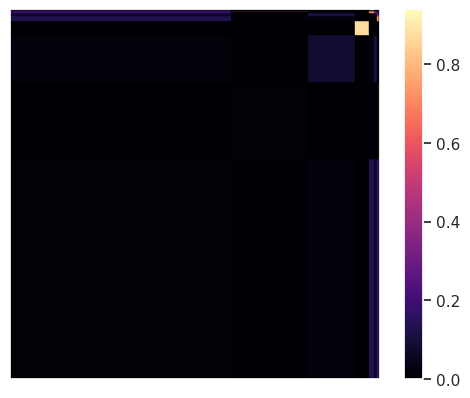

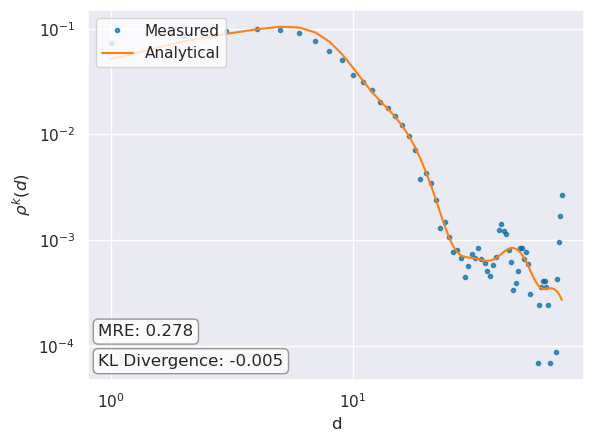

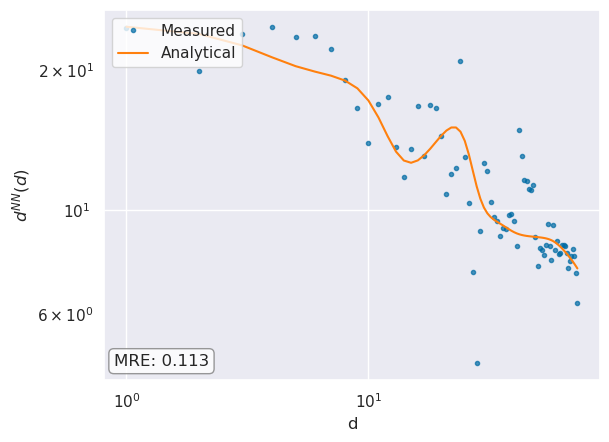

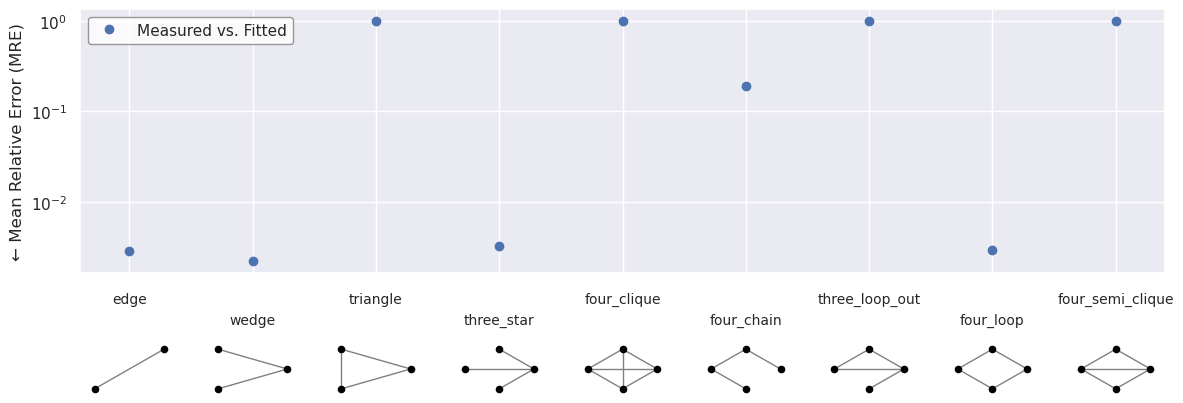

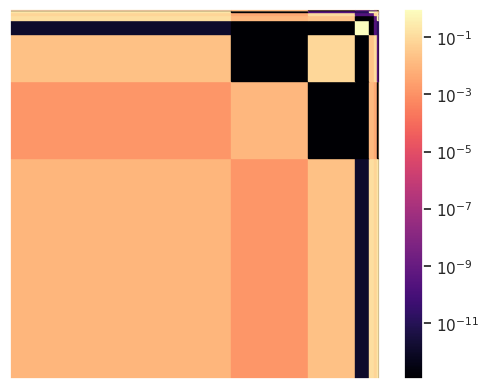

In [13]:
mfnf.find_P_l(m=11, k=1, one_shot=True)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/celegans_neural_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #xlim=,
    #ylim=,
    #filename = "figures/celegans_neural_log_plot.pdf"
)

#### Looking at 'second best' results. Prefreably without a peak in dnn

Energy: 8.740222255338601
KL-divergence: 0.011986361200083655
KLD augumented energy: 5.313247016410021


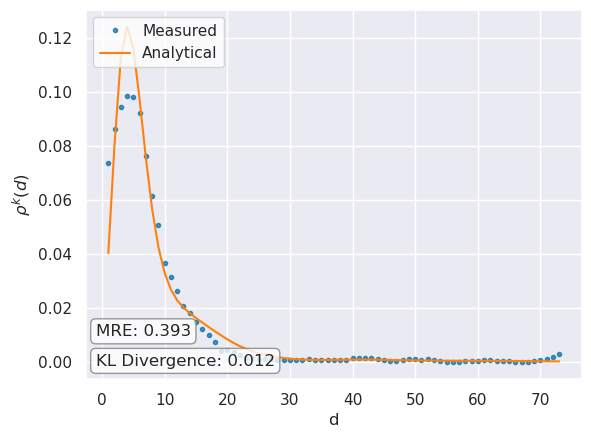

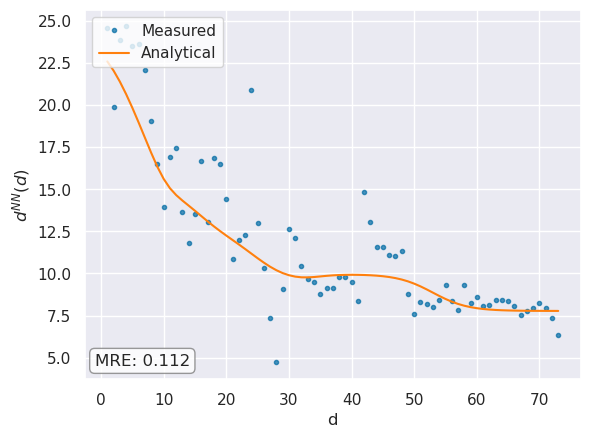

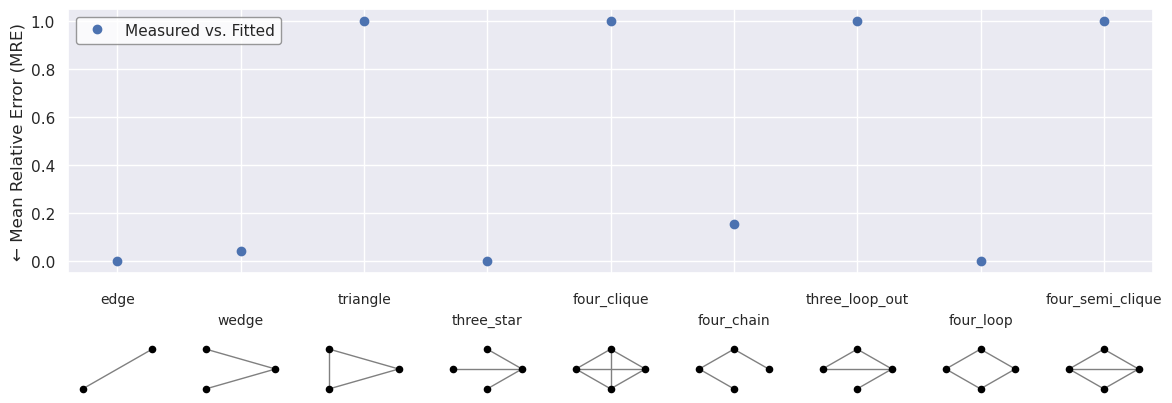

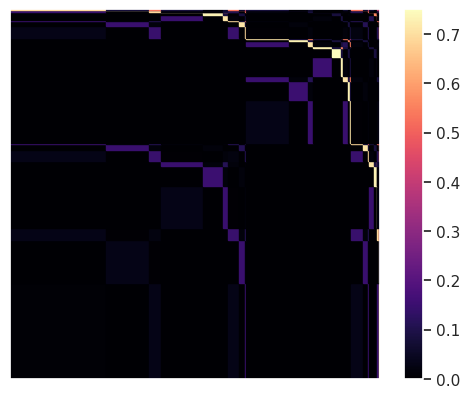

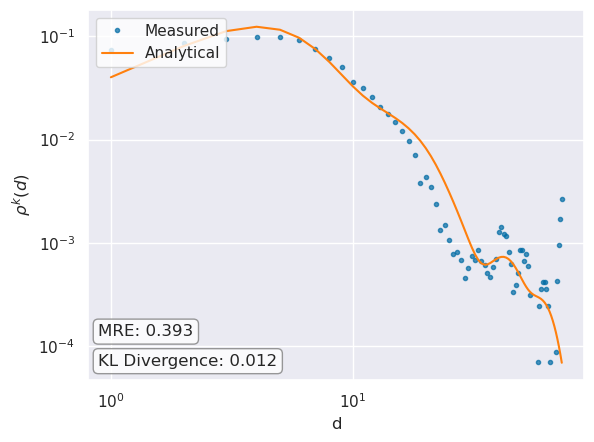

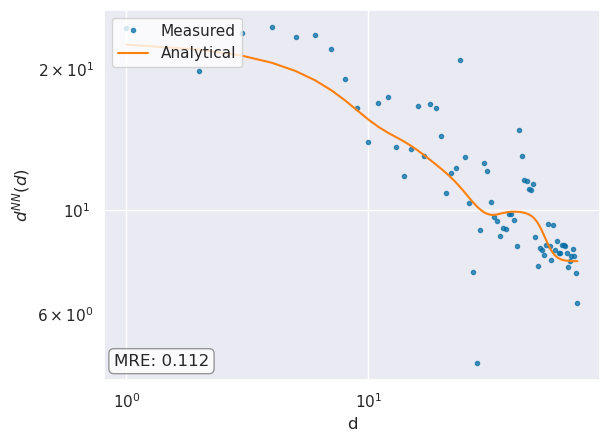

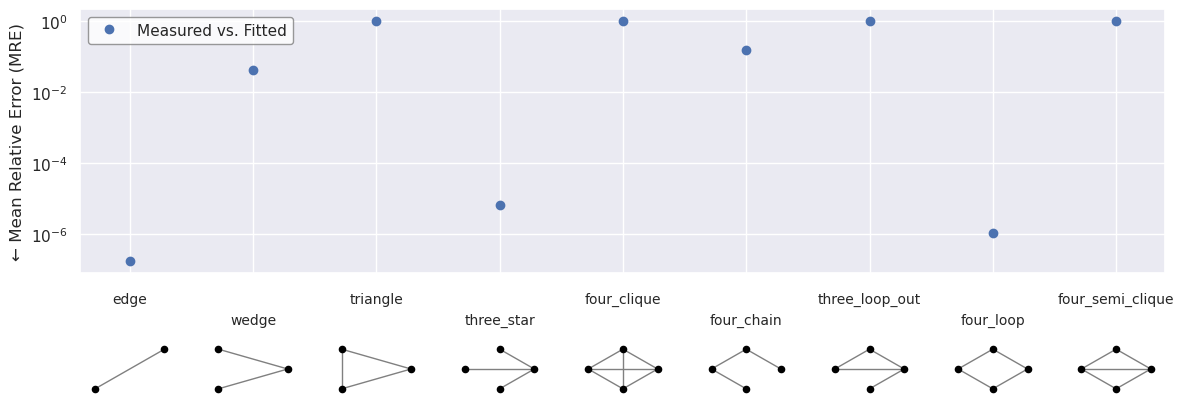

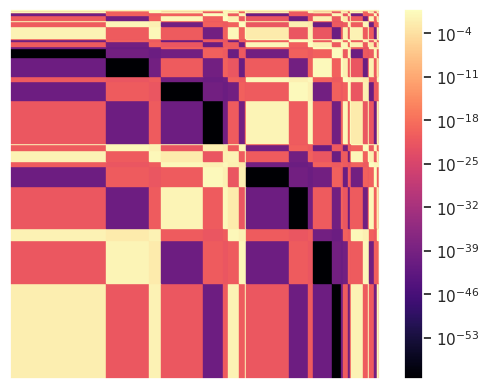

In [14]:
mfnf.find_P_l(m=3, k=3, one_shot=True)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/celegans_neural_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #xlim=,
    #ylim=,
    #filename = "figures/celegans_neural_log_plot.pdf"
)

# Bootstrapping Stability

In [19]:
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size,
    ci = 0.95,
    medoid = 'mean'
)

Gathering statistics (30 runs)...


100%|██████████| 30/30 [36:31<00:00, 73.06s/it]

Bootstrapping: Resampling 200 times...


Bootstrapping finished in 0:00:00.296637
Energy = 8.73 (8.72, 8.74)
l = [0.66 (0.60, 0.66), 0.26 (0.26, 0.32), 0.08 (0.08, 0.08)]
P = [
[0.18 (0.18, 0.19), 0.00 (0.00, 0.00), 0.85 (0.84, 0.92)],

[0.00 (0.00, 0.00), 0.98 (0.77, 1.00), 0.09 (0.09, 0.10)],

[0.85 (0.84, 0.92), 0.09 (0.09, 0.10), 0.66 (0.63, 0.81)]
]


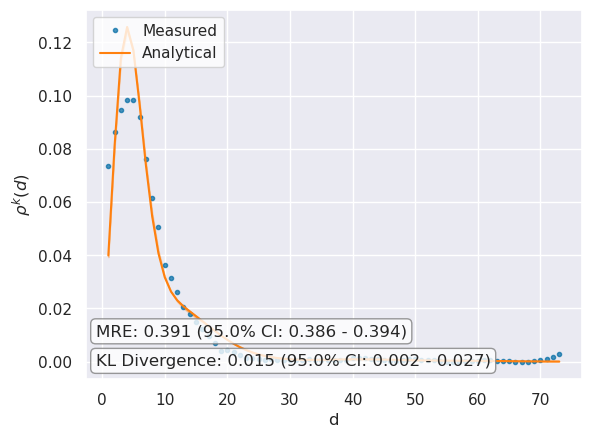

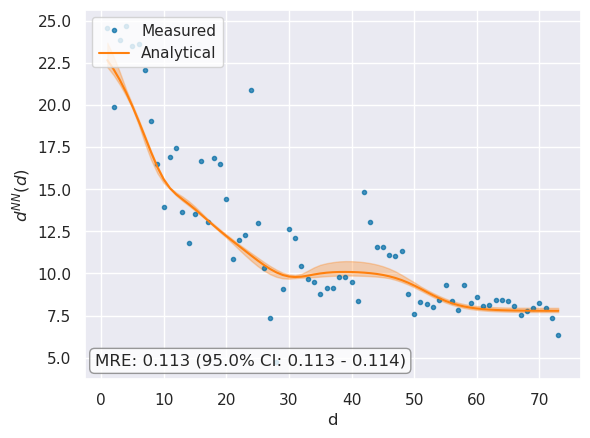

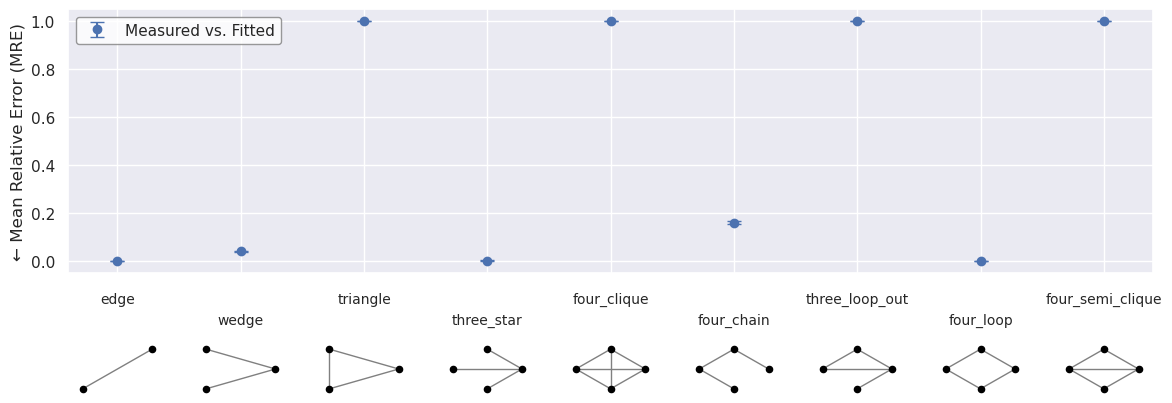

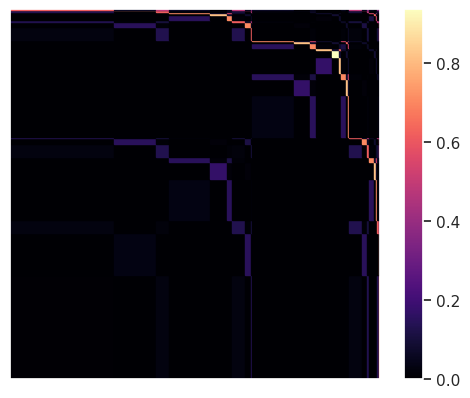

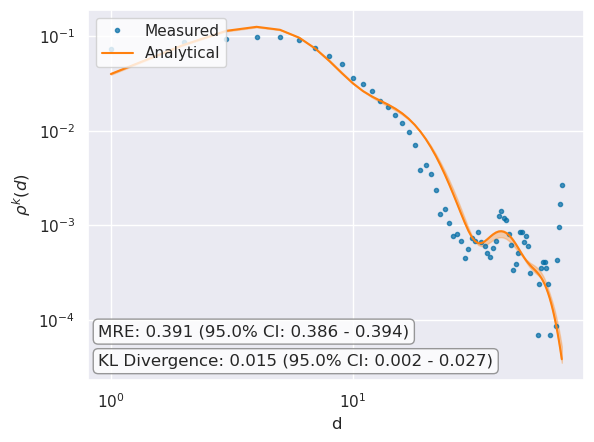

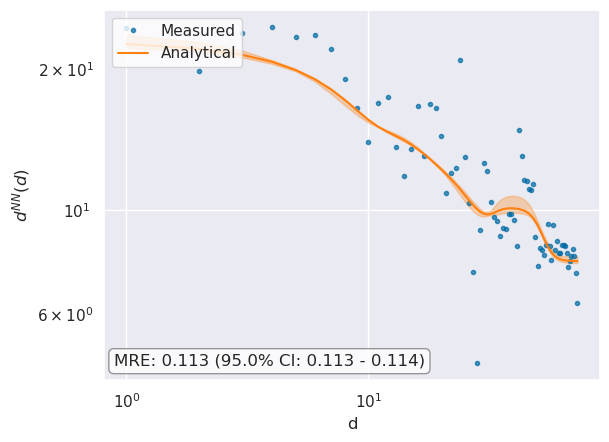

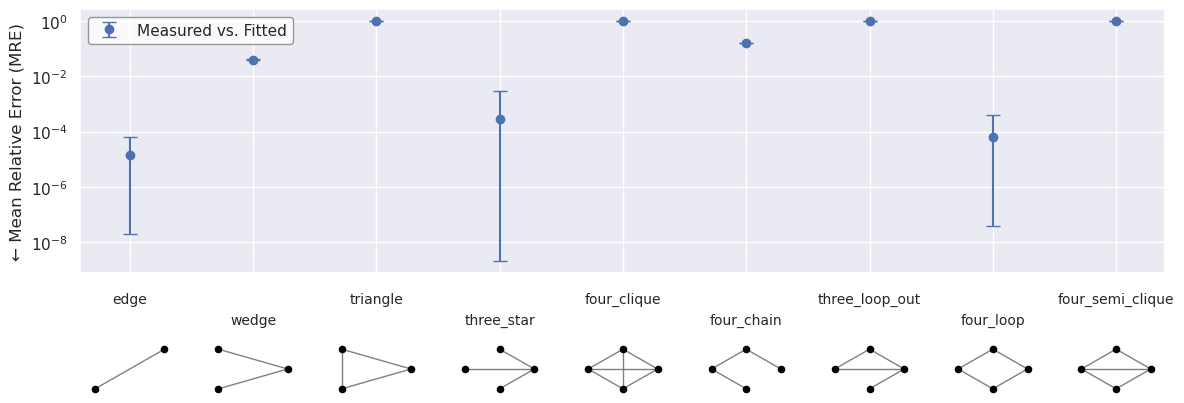

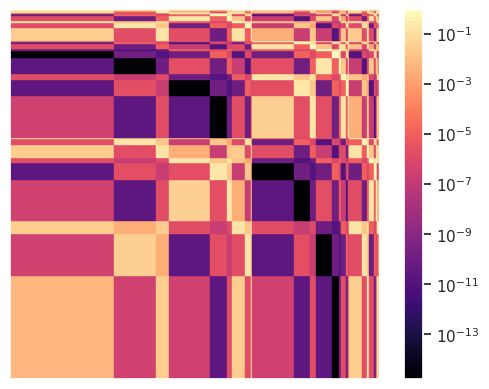

In [21]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/celegans_neural_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #xlim=,
    #ylim=,
    filename = "figures/celegans_neural_log_plot.pdf"
)

# Generate Variants

Initializing...
0.0010716915130615234
Calculating betweenness...
Done.
Calculating node positions...
Done.


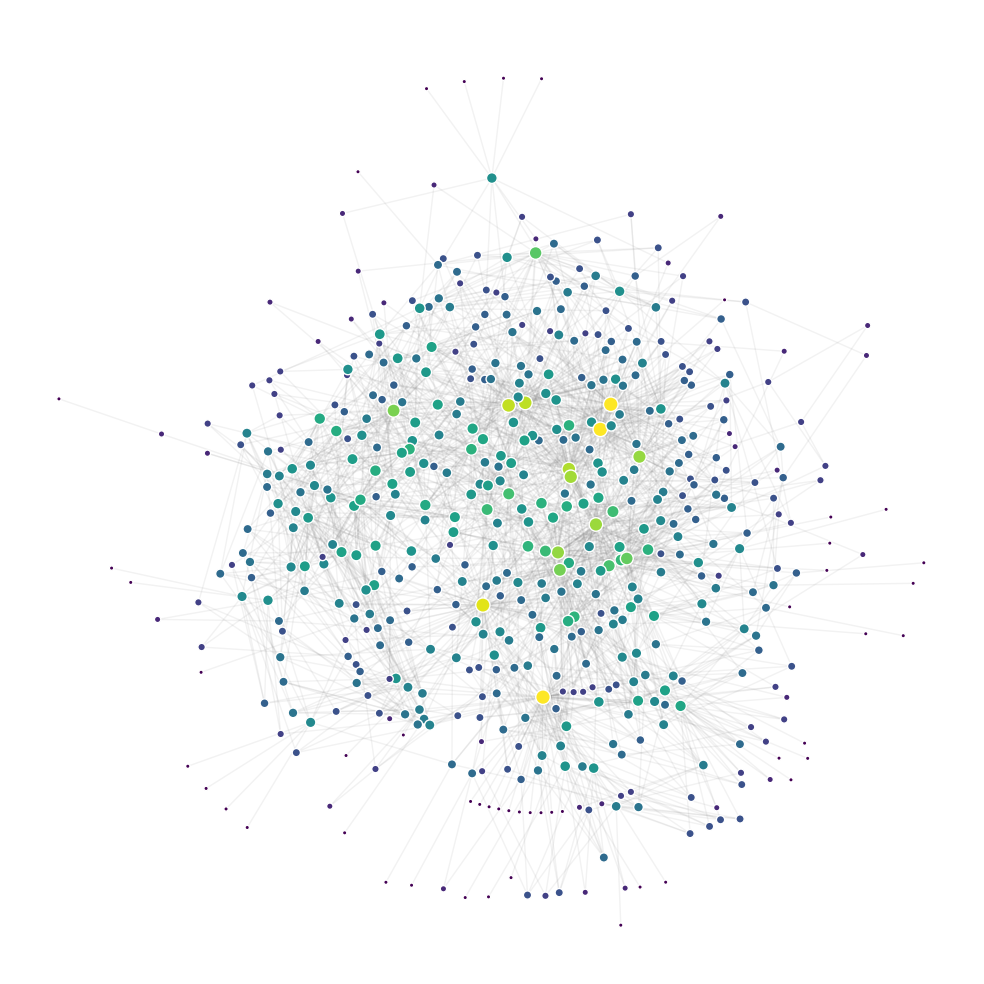

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 474.16it/s]

Refining network structure...
Refining 6 outlier nodes...



100%|██████████| 32/32 [00:00<00:00, 831.38it/s]

Refining 6 outlier nodes...



100%|██████████| 32/32 [00:00<00:00, 702.43it/s]

Refining 6 outlier nodes...



100%|██████████| 32/32 [00:00<00:00, 661.51it/s]


Calculating betweenness...
Done.
Calculating node positions...
Done.


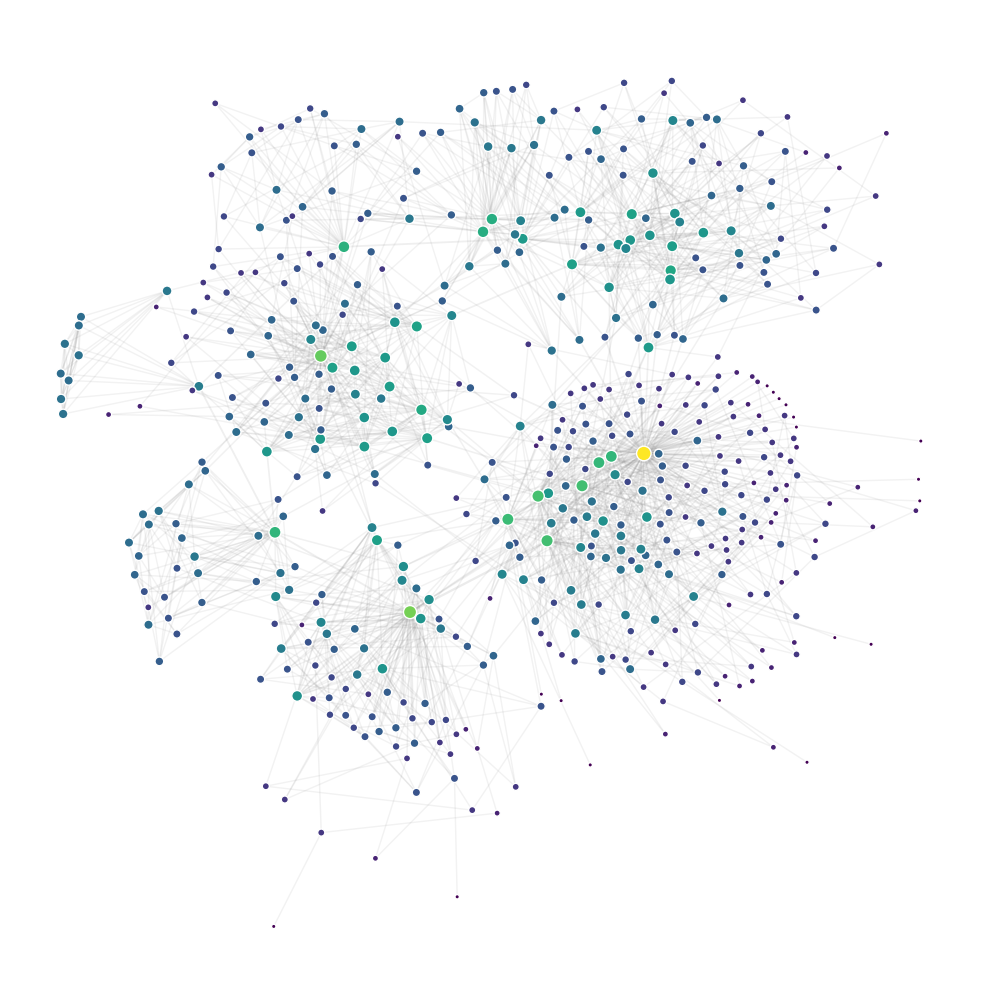

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 378.89it/s]

Refining network structure...
Refining 5 outlier nodes...



100%|██████████| 32/32 [00:00<00:00, 629.19it/s]


Calculating betweenness...
Done.
Calculating node positions...
Done.


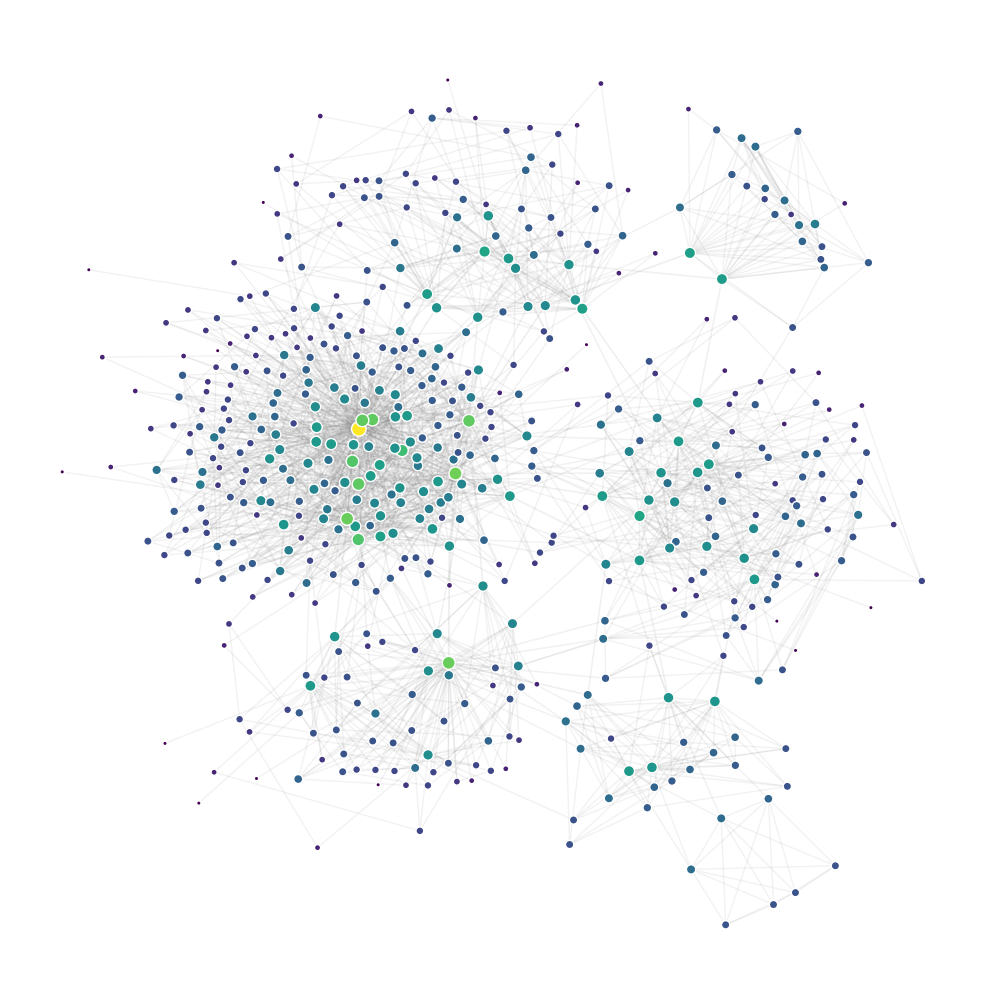

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 434.52it/s]

Refining network structure...
Refining 4 outlier nodes...



100%|██████████| 32/32 [00:00<00:00, 616.58it/s]

Refining 4 outlier nodes...



100%|██████████| 32/32 [00:00<00:00, 603.17it/s]

... (25 outputs left out)


100%|██████████| 32/32 [00:00<00:00, 672.26it/s]

Refining 1 outlier nodes...



100%|██████████| 32/32 [00:00<00:00, 689.52it/s]


Calculating betweenness...
Done.
Calculating node positions...
Done.


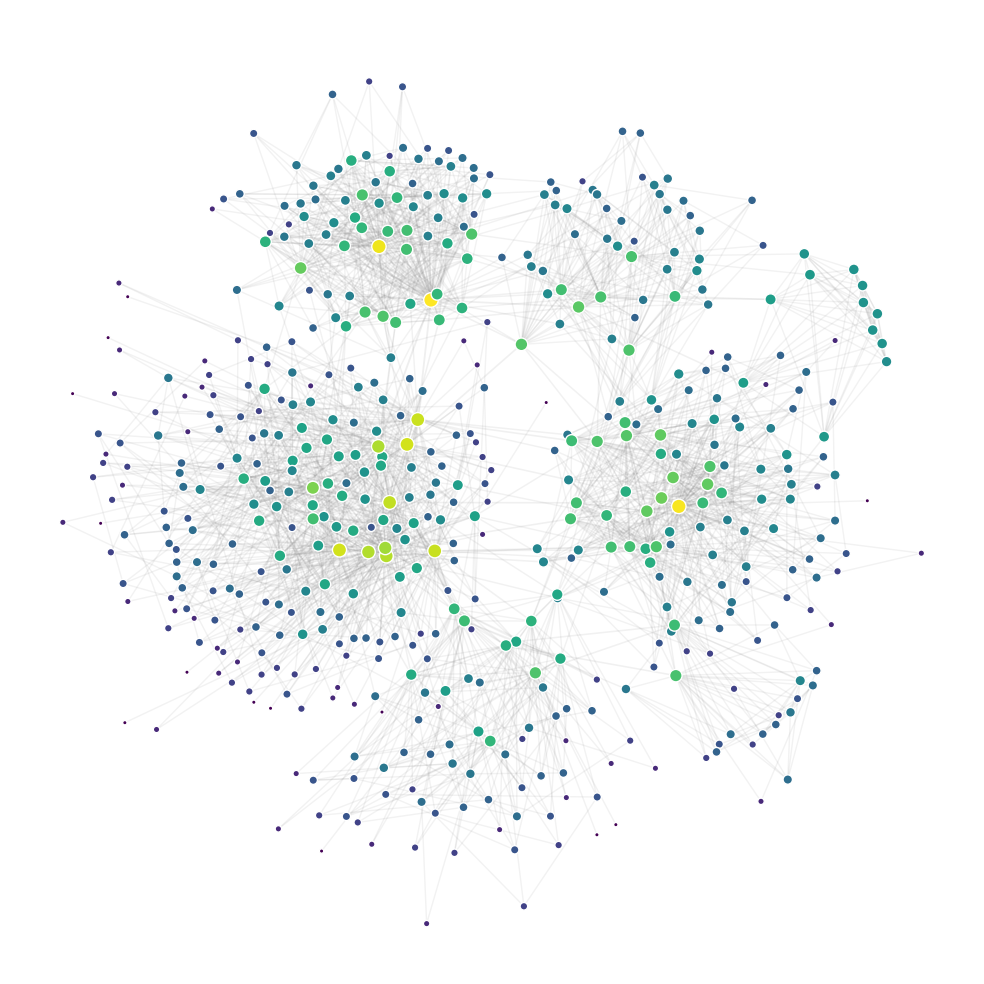

In [22]:
mfnf.generate_variants(
    plot_options = {
        'layout_func': nx.kamada_kawai_layout,
        'figsize': (10,10),
        'filename':  "figures/celegans_neural_variants.pdf"
    },
    filename = "variant_networks/celegans_neural_variants.graphml"
)